# Example: Backtesting a Strategy from the Menu
In this example, we backtest one strategy from [the strategy menu](strategies/CHEME-5660-L15a-Strategy-Menu-Fall-2026.ipynb) on the real market, from January 2, 2025, to November 24, 2026.

We start with betting against beta (BAB) and look at the long and short positions from one decision. Then we compare its wealth with `SPY` and mark the days a trigger fired.

Tasks 2 and 3 extend the backtest. We place the strategy among the saved results and run it again with updated estimates.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Backtest a strategy on the real market:__ Run the strategy we choose, starting with USD 100,000. Compare its wealth with the same investment in `SPY`, and mark the days a trigger fired.
> * __Place the strategy on the menu:__ Compare the strategy's Sharpe ratio and largest drawdown with those of `SPY` and of the 3,456 saved backtests of the menu.
> * __Update the estimates:__ Run the same strategy with estimates that update on each trading day, and compare the two backtests.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, and loads the functions in the local `src` directory. It also loads the strategy files in the `strategies` folder and [the strategy menu](strategies/menu.jl).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/). The `MPC` module of the course package holds the code of the trading method.

### Data
We load the daily prices of the stocks and exchange-traded funds (ETFs) that the trading method can pick, from January 4, 2016, to November 24, 2026, with [the `MPC.load_l15a_market(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-trading/#VLQuantitativeFinancePackage.MPCPortfolio.load_l15a_market-Tuple{AbstractString}). Each stock has its sector in the [Global Industry Classification Standard (GICS)](https://www.msci.com/our-solutions/indexes/gics), and each ETF has the sector `ETF`. The trading method uses `SPY` as the market and as the market hedge.

We store the data in the [`md::MPC.MyMarketData` variable](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.MyMarketData). The `md.open` and `md.close` fields hold the opening and closing prices (days × tickers, USD/share), `md.volume` the volumes (shares/day), and `md.g_f` the 3-month Treasury bill rate of each day (1/yr). For a ticker that began trading after January 4, 2016, the price and volume fields hold `NaN` before its first trading day:

In [2]:
md = let

    # load the prices, volumes, sectors, and risk-free rates from January 4, 2016, through November 24, 2026 -
    md = MPC.load_l15a_market(_PATH_TO_DATA; start = Date(2016, 1, 4), stop = Date(2026, 11, 24));

    # checks -
    @assert md.dates[1] == Date(2016, 1, 4) && md.dates[end] == Date(2026, 11, 24) "the data must run from 2016-01-04 to 2026-11-24"
    @assert size(md.close) == (length(md.dates), length(md.tickers)) "one closing price per trading day and ticker"
    @assert all(md.close[searchsortedfirst(md.dates, Date(2025, 1, 2)):end, :] .> 0) "every ticker must have a price on every trading day of the backtest"

    # return -
    md
end;
println("$(length(md.tickers)) tickers ($(count(md.sector .== "ETF")) ETFs), $(length(md.dates)) trading days");

505 tickers (14 ETFs), 2740 trading days


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values. The names on the menu are listed in [the strategy menu](strategies/CHEME-5660-L15a-Strategy-Menu-Fall-2026.ipynb):

In [3]:
train_start = Date(2016, 1, 4); # first trading day of the training period
train_stop = Date(2024, 12, 31); # last trading day of the training period
run_start = Date(2025, 1, 2); # first trading day of the backtest (the four dates must stay as set to match the saved backtests of Task 2)
run_stop = Date(2026, 11, 24); # last trading day of the backtest
my_picking = "gamma by sector"; # the picking rule: a name on the picking menu, for example "random liquid"
my_weighting = "BAB"; # the weighting rule: a name on the weighting menu, for example "equal weight"
my_hedge = false; # true runs the market hedge, and false runs without it
my_seed = 5660; # seed of the backtest's random draws; the saved backtests use 5660, and 1 to 30 for the random picking rules

___

## Task 1: Backtest a Strategy on the Real Market
In this task, we backtest the strategy we chose in the constants on the real market, and compare it with `SPY`.

First, we set up the backtest:
* [The `MPC.load_study(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.load_study-Tuple{AbstractString}) reads the default settings of the trading method. [The `MPC.with_settings(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.with_settings-Tuple{VLQuantitativeFinancePackage.MPCPortfolio.MyStudySettings}) sets our dates, our hedge choice, and the fixed estimates.
* [The `MPC.calibrate(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.calibrate-Tuple{VLQuantitativeFinancePackage.MPCPortfolio.MyMarketData}) fits the single index model of every stock on its 2016 to 2024 prices. We also load the generator's forecast models of the band-exit trigger with [the `JLD2.load(...)` function](https://juliaio.github.io/JLD2.jl/stable/basic_usage/#FileIO-interface).
* [The `MPC.build_context(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/#VLQuantitativeFinancePackage.MPCPortfolio.build_context-Tuple{VLQuantitativeFinancePackage.MPCPortfolio.MyMarketData,%20VLQuantitativeFinancePackage.MPCPortfolio.MyCalibration,%20VLQuantitativeFinancePackage.MPCPortfolio.MyStudySettings}) computes the inputs that every backtest with these settings shares: the estimates, the preference weights, and the tickers the market hedge can buy on each day.

We store the settings, the fit, the forecast models, and the shared inputs in the `settings::MPC.MyStudySettings`, `calib::MPC.MyCalibration`, `fm::MPC.MyForecastModels`, and `ctx_fixed::MPC.MyStudyContext` variables. The `W_spy::Vector{Float64}` variable holds the wealth of the same investment in `SPY` (USD), and the `spy_scores::NamedTuple` variable holds its scores from [the `MPC.growth_scorecard(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-trading/#VLQuantitativeFinancePackage.MPCPortfolio.growth_scorecard-Tuple{Vector{Float64},%20Vector{Float64},%20Vector{Float64}}):

In [4]:
settings, calib, fm, ctx_fixed, W_spy, spy_scores = let

    # the settings of the trading method, with our dates, our hedge choice, and fixed estimates -
    base = MPC.load_study(MPC.default_study_path()).settings;
    settings = MPC.with_settings(base; start = run_start, stop = run_stop, train_start = train_start,
        train_stop = train_stop, hedge = my_hedge, estimates = "fixed");

    # fit the single index model of every stock on 2016 to 2024, and load the forecast models of the band trigger -
    calib = MPC.calibrate(md; train_start = train_start, train_stop = train_stop);
    fm = JLD2.load(joinpath(_PATH_TO_DATA, "L15a-Forecast-Models.jld2"), "fm");

    # the inputs that every backtest with these settings shares -
    ctx = MPC.build_context(md, calib, settings; fm = fm);

    # the wealth of the same investment in SPY on the run days (USD), and its scores -
    spy = md.spy_close[ctx.rows]; # SPY closes on the run days (USD/share)
    W_spy = zeros(length(spy));
    for k ∈ 1:length(spy)
        W_spy[k] = settings.W0 * spy[k] / spy[1];
    end
    spy_scores = MPC.growth_scorecard(W_spy, spy, md.g_f[ctx.rows]);

    # checks -
    @assert md.dates[first(ctx.rows)] == run_start && md.dates[last(ctx.rows)] == run_stop "the backtest must run from run_start to run_stop"

    # return -
    settings, calib, fm, ctx, W_spy, spy_scores
end;

__Let's backtest the strategy__. [The `find_rule(...)` function](strategies/menu.jl) looks up our picking rule on [the `picking_menu(...)` list](strategies/menu.jl), and our weighting rule on [the `weighting_menu(...)` list](strategies/menu.jl). [The `MPC.build(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-trading/#VLQuantitativeFinancePackage.build-Tuple{Type{VLQuantitativeFinancePackage.MPCPortfolio.MyStudyRun},%20NamedTuple}) puts the strategy and the settings into one run. Then [the `MPC.score_study(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-trading/#VLQuantitativeFinancePackage.MPCPortfolio.score_study-Tuple{VLQuantitativeFinancePackage.MPCPortfolio.MyStudyContext,%20VLQuantitativeFinancePackage.MPCPortfolio.MyStudyRun}) backtests the run and scores it against `SPY`.

We store the backtest in the `backtest_fixed::NamedTuple` variable. The `result` field holds the wealth of each day and the decisions, and the `scorecard` field holds the scores, such as the Sharpe ratio and the largest drawdown:

In [5]:
backtest_fixed = let

    # the strategy: the picking rule and the weighting rule from the menu -
    picking = find_rule(picking_menu(settings), my_picking);
    weighting = find_rule(weighting_menu(settings), my_weighting);
    run = MPC.build(MPC.MyStudyRun, (settings = settings, allocator = weighting.rule, screen = picking.screen,
        seed = my_seed, label = my_picking * " | " * my_weighting));

    # backtest the strategy, and score it against SPY -
    backtest = MPC.score_study(ctx_fixed, run);
    println("$(nrow(backtest.result.decisions)) decisions; wealth on $(run_stop): USD $(round(backtest.scorecard.terminal, digits = 2))");

    # checks -
    @assert all(isfinite, backtest.result.equity) "the wealth must be a number on every day"

    # return -
    backtest
end;

39 decisions; wealth on 2026-11-24: USD 93836.56


Let's inspect the target portfolio from the first decision that gives us a position worth more than 0.1% of wealth. The table shows up to three of the largest positions on each side. A negative weight is a short position.

In [6]:
let
    result = backtest_fixed.result;
    shown = false;

    for (k, day) in enumerate(result.decisions.date)
        # Find the first decision with target positions above the engine's trading cutoff -
        weights = copy(result.targets[day]);
        spy_short = result.decisions.spy_share[k];
        if spy_short > 0.0
            weights["SPY"] = -spy_short;
        end
        longs = Tuple{Float64,String}[];
        shorts = Tuple{Float64,String}[];
        for (ticker, weight) in weights
            if weight > 0.001
                push!(longs, (-weight, ticker));
            elseif weight < -0.001
                push!(shorts, (weight, ticker));
            end
        end
        if isempty(longs) && isempty(shorts)
            continue;
        end

        # Show the largest weights by magnitude on each side -
        sort!(longs);
        sort!(shorts);
        rows = DataFrame(side = String[], ticker = String[], beta = Float64[], weight_pct = Float64[]);
        row = searchsortedfirst(result.dates, day);
        for (side, tickers) in (("Long", longs), ("Short", shorts))
            for (_, ticker) in first(tickers, min(3, length(tickers)))
                beta = 1.0; # SPY has market beta 1
                if ticker != "SPY"
                    j = searchsortedfirst(md.tickers, ticker);
                    beta = ctx_fixed.sim.β[row, j];
                end
                push!(rows, (side, ticker, beta, 100 * weights[ticker]));
            end
        end

        beta_portfolio = result.decisions.beta_target[k] - spy_short;
        println("Decision on ", day, ". Target portfolio beta ", round(beta_portfolio; digits = 2), ".");
        pretty_table(rows;
            column_labels = ["side", "ticker", "beta", "target weight (%)"],
            formatters = [fmt__printf("%.2f", [3]), fmt__printf("%+.2f", [4])],
            table_format = TextTableFormat(borders = text_table_borders__compact),
            fit_table_in_display_horizontally = false
        );
        shown = true;
        break;
    end

    if !shown
        println("All target weights were within the display cutoff.");
    end
end

Decision on 2025-01-02. Target portfolio beta 0.41.
 ------- -------- ------ -------------------
   side   ticker   beta   target weight (%)
 ------- -------- ------ -------------------
   Long      WMT   0.48              +10.00
   Long      LLY   0.67              +10.00
   Long     CASY   0.69              +10.00
  Short     CVNA   2.39               -4.43
  Short      APP   2.15               -4.07
  Short     PLTR   1.94               -3.72
 ------- -------- ------ -------------------


With the starting BAB settings, the long rows have lower betas than the short rows. The target portfolio has a beta of 0.41 after the engine applies the trading limits.


Let's plot the wealth of the strategy and of the same investment in `SPY` with [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot). [The `scatter!(...)` function](https://docs.juliaplots.org/stable/api/#Plots.scatter!-Tuple) marks each day a trigger fired, with one color for each trigger. How often does the strategy make a new decision?

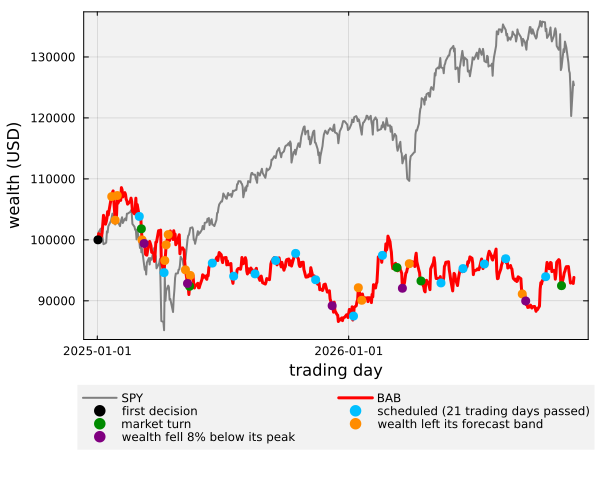

In [7]:
let

    # initialize: the run days, and the strategy's wealth (USD) -
    run_dates = backtest_fixed.result.dates;
    W = backtest_fixed.result.equity;

    # the triggers, with a legend label and a color for each one -
    triggers = [:initial, :horizon_elapsed, :market_turn, :band_exit, :drawdown, :beta_over_cap, :cash_revisit];
    labels = ["first decision", "scheduled ($(settings.T) trading days passed)", "market turn", "wealth left its forecast band",
        "wealth fell $(round(Int, 100 * settings.D_max))% below its peak", "market sensitivity over its limit",
        "back from cash"];
    colors = [:black, :deepskyblue1, :green4, :darkorange, :purple, :gold, :brown];
    decisions = backtest_fixed.result.decisions;

    # display options used in this cell -
    # lw: Set the line width in points.
    # c: Choose the series color.
    # label: Set the legend entry.
    # bg: Set the plot background color.
    # background_color_outside: Set the background color outside the plotting grid.
    # framestyle: Use a box around the plotting area.
    # fg_legend: Set the legend foreground color; transparent removes its border.
    # legend: Set where the legend goes; :outerbottom puts it below the plotting area, so it does not cover the wealth.
    # legendcolumns: Set the number of legend columns.
    # size: Set the figure width and height in pixels.
    # yformatter: Write the axis numbers in full, without scientific notation.
    # ms: Set the marker size in points.
    # msw: Set the marker outline width in points.
    p = plot(run_dates, W_spy, lw = 2, c = :gray50, label = "SPY", bg = "gray95", background_color_outside = "white",
        framestyle = :box, fg_legend = :transparent, legend = :outerbottom, legendcolumns = 2, size = (600, 500),
        yformatter = :plain);
    plot!(p, run_dates, W, lw = 3, c = :red, label = my_weighting);

    # one marker on the strategy's wealth for each decision, colored by its trigger -
    for k ∈ 1:length(triggers)
        days = Date[];
        wealth = Float64[];
        for i ∈ 1:nrow(decisions)
            if decisions.reason[i] == triggers[k]
                s = searchsortedfirst(run_dates, decisions.date[i]); # position of the decision day
                push!(days, run_dates[s]);
                push!(wealth, W[s]);
            end
        end
        if length(days) > 0
            scatter!(p, days, wealth, ms = 5, msw = 0, c = colors[k], label = labels[k]);
        end
    end
    xlabel!(p, "trading day");
    ylabel!(p, "wealth (USD)");

    # checks -
    for i ∈ 1:nrow(decisions)
        @assert decisions.reason[i] ∈ triggers "every decision must have one of the triggers in the legend"
    end

    # return -
    p
end

> __What do we see?__ With the starting BAB settings, the engine made 39 decisions over 476 trading days. The 21-day schedule alone would have given 23. BAB ended at USD 93,837, and the same investment in `SPY` ended at USD 125,365.


___

## Task 2: Place the Strategy on the Menu
In this task, we compare the strategy with the 3,456 saved backtests of the menu. They cover each of the 324 strategies, with 30 seeds for each random picking rule.

We load the saved backtests with the `JLD2.load(...)` function and store the scores in the `menu_backtests::DataFrame` variable, with one row per backtest. Each row holds the strategy's choices and its scores, for example its Sharpe ratio, its largest drawdown, and its wealth on the last day. We also check that our backtest matches its saved row:

In [8]:
menu_backtests = let

    # load the saved scores of every backtest on the menu -
    saved = JLD2.load(joinpath(_PATH_TO_DATA, "L15a-Strategies-Real-2025-2026.jld2"));
    df = saved["summary"];

    # find the saved row of our strategy -
    hedge_name = "hedge off";
    if my_hedge == true
        hedge_name = "hedge on";
    end
    label = my_picking * " | " * my_weighting * " | " * hedge_name * " | fixed | seed " * string(my_seed);
    ours = findall(df.strategy .== label); # rows with our strategy's label (one row, or none for an unsaved seed)
    println("$(nrow(df)) saved backtests; $(count(df.status .== "ok")) ran without an error");

    # checks -
    @assert nrow(df) == 3456 "the menu must have 3,456 backtests"
    @assert all(df.status .== "ok") "every saved backtest must have run without an error"
    @assert length(ours) <= 1 "each strategy label must appear at most once"
    if length(ours) == 1
        @assert isapprox(df.terminal[ours[1]], backtest_fixed.scorecard.terminal; rtol = 1e-6) "our backtest must match its saved row"
    end

    # return -
    df
end;

3456 saved backtests; 3456 ran without an error


Let's plot the Sharpe ratio of each backtest against its largest drawdown. The green points share our weighting rule, and the blue points share our picking rule. Does our strategy beat `SPY` with a higher Sharpe ratio and a smaller drawdown?

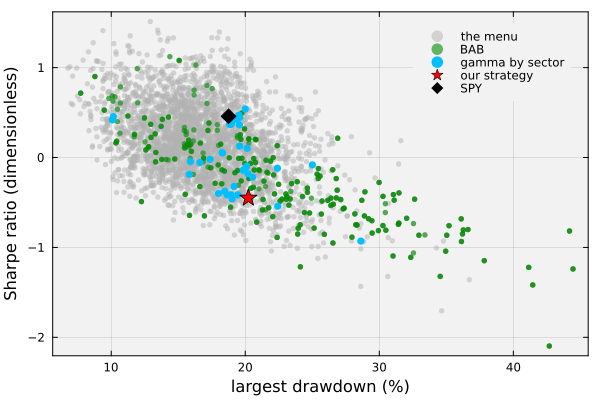

In [9]:
let

    # initialize: the backtests of our picking rule and of our weighting rule -
    ours_picking = findall(menu_backtests.picking .== my_picking);
    ours_weighting = findall(menu_backtests.weighting .== my_weighting);

    # plot: the menu, our picking rule, our weighting rule, our strategy, and SPY (see Task 1 for the display options) -
    # ma: Set the marker opacity, from 0 (clear) to 1 (solid).
    # m: Choose the marker shape.
    p = scatter(100 .* menu_backtests.max_drawdown, menu_backtests.sharpe, ms = 3, msw = 0, c = :gray70, ma = 0.5,
        label = "the menu", bg = "gray95", background_color_outside = "white", framestyle = :box,
        fg_legend = :transparent, legend = :topright);
    scatter!(p, 100 .* menu_backtests.max_drawdown[ours_weighting], menu_backtests.sharpe[ours_weighting], ms = 3,
        msw = 0, c = :green4, ma = 0.6, label = my_weighting);
    scatter!(p, 100 .* menu_backtests.max_drawdown[ours_picking], menu_backtests.sharpe[ours_picking], ms = 4,
        msw = 0, c = :deepskyblue1, label = my_picking);
    scatter!(p, [100 * backtest_fixed.scorecard.max_drawdown], [backtest_fixed.scorecard.sharpe], ms = 9,
        m = :star5, c = :red, label = "our strategy");
    scatter!(p, [100 * spy_scores.max_drawdown], [spy_scores.sharpe], ms = 8, m = :diamond, c = :black, label = "SPY");
    xlabel!(p, "largest drawdown (%)");
    ylabel!(p, "Sharpe ratio (dimensionless)");

    # checks -
    @assert length(ours_picking) > 0 && length(ours_weighting) > 0 "our rules must be on the menu"

    # return -
    p
end

> __What do we see?__ Across the menu, a larger drawdown goes with a smaller Sharpe ratio. Only 762 of the 3,456 backtests have a higher Sharpe ratio than `SPY`, and 651 of these also have a smaller drawdown.

___

## Task 3: Update the Estimates
In this task, we run the same strategy again with updated estimates, and change nothing else.

With updated estimates, the trading method updates the single index model of every stock on each trading day, starting from the 2016 to 2024 fit. Because the estimates are part of the shared inputs, we build new shared inputs with the `MPC.build_context(...)` function.

We store the updated backtest in the `backtest_updated::NamedTuple` variable:

In [10]:
backtest_updated = let

    # the same settings, with updated estimates, and the inputs that the updated backtests share -
    settings_updated = MPC.with_settings(settings; estimates = "updated");
    ctx_updated = MPC.build_context(md, calib, settings_updated; fm = fm);

    # the same strategy, backtested with the updated estimates -
    picking = find_rule(picking_menu(settings_updated), my_picking);
    weighting = find_rule(weighting_menu(settings_updated), my_weighting);
    run = MPC.build(MPC.MyStudyRun, (settings = settings_updated, allocator = weighting.rule, screen = picking.screen,
        seed = my_seed, label = my_picking * " | " * my_weighting * " | updated"));
    backtest = MPC.score_study(ctx_updated, run);
    println("$(nrow(backtest.result.decisions)) decisions; wealth on $(run_stop): USD $(round(backtest.scorecard.terminal, digits = 2))");

    # checks -
    @assert backtest.result.dates == backtest_fixed.result.dates "both backtests must run on the same days"
    @assert all(isfinite, backtest.result.equity) "the wealth must be a number on every day"

    # return -
    backtest
end;

43 decisions; wealth on 2026-11-24: USD 109655.72


Let's plot the wealth of the two backtests and of `SPY`. Do the updated estimates end with more wealth?

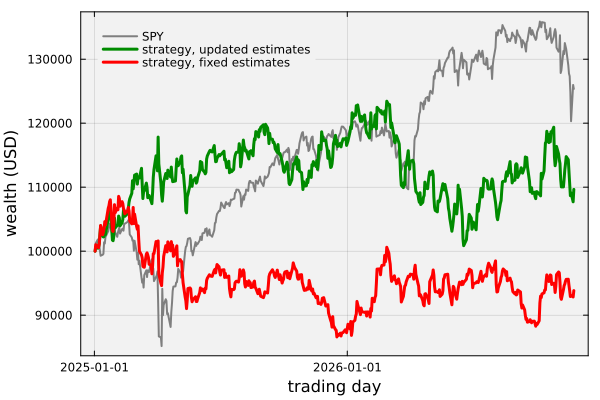

In [11]:
let

    # initialize: the run days -
    run_dates = backtest_fixed.result.dates;

    # plot: SPY and the two backtests (see Task 1 for the display options) -
    p = plot(run_dates, W_spy, lw = 2, c = :gray50, label = "SPY", bg = "gray95", background_color_outside = "white",
        framestyle = :box, fg_legend = :transparent, legend = :topleft, yformatter = :plain);
    plot!(p, run_dates, backtest_updated.result.equity, lw = 3, c = :green4, label = "strategy, updated estimates");
    plot!(p, run_dates, backtest_fixed.result.equity, lw = 3, c = :red, label = "strategy, fixed estimates");
    xlabel!(p, "trading day");
    ylabel!(p, "wealth (USD)");

    # return -
    p
end

Finally, let's compare the scores of the two backtests and of `SPY` with [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table):

In [12]:
let

    # initialize: one row per backtest, and one for SPY -
    df = DataFrame(backtest = String[], growth = Float64[], sharpe = Float64[], drawdown = Float64[],
        wealth = Float64[], decisions = Int[]);
    for (name, backtest) ∈ [("fixed estimates", backtest_fixed), ("updated estimates", backtest_updated)]
        scores = backtest.scorecard;
        push!(df, (name, scores.realized_growth, scores.sharpe, 100 * scores.max_drawdown, scores.terminal,
            nrow(backtest.result.decisions)));
    end
    push!(df, ("SPY", spy_scores.realized_growth, spy_scores.sharpe, 100 * spy_scores.max_drawdown,
        spy_scores.terminal, 1));

    # let's display the scores in a table -
    pretty_table(df;
        column_labels = ["backtest", "growth rate (1/yr)", "Sharpe ratio", "largest drawdown (%)", "wealth (USD)",
            "decisions"], # displayed column headings
        alignment = [:l, :r, :r, :r, :r, :r], # :l aligns a column left; :r aligns it right
        formatters = [fmt__printf("%.3f", [2, 3]), fmt__printf("%.1f", [4]), fmt__printf("%.2f", [5])], # decimals
        table_format = TextTableFormat(borders = text_table_borders__compact), # compact separator characters
        fit_table_in_display_horizontally = false, # keep all columns
        fit_table_in_display_vertically = false # keep all rows
    );
end

 ------------------- -------------------- -------------- ---------------------- -------------- -----------
  backtest            growth rate (1/yr)   Sharpe ratio   largest drawdown (%)   wealth (USD)   decisions
 ------------------- -------------------- -------------- ---------------------- -------------- -----------
  fixed estimates                 -0.034         -0.450                   20.2       93836.56          39
  updated estimates                0.049          0.053                   18.3      109655.72          43
  SPY                              0.120          0.459                   18.8      125364.96           1
 ------------------- -------------------- -------------- ---------------------- -------------- -----------


> __What do we see?__ The figure and the table depend on the strategy we chose. Across the menu, the updated backtest ends with more wealth in 792 of the 1,728 pairs of backtests that differ only in the estimates. It has the smaller drawdown in only 515 pairs.

___

## Summary
In this example, we backtested one strategy from the menu on the real market, placed it among the saved backtests of the whole menu, and ran it again with updated estimates.

> __Key Takeaways:__
>
> * __Triggers add decisions to the 21-day schedule:__ We backtested the strategy we chose on the real market and marked the days a trigger fired. The 21-day schedule alone gives 23 decisions over the 476 trading days, and a backtest on the menu made 25 to 66.
> * __Most strategies on the menu have a lower Sharpe ratio than `SPY`:__ We placed the strategy among the 3,456 saved backtests of the menu by its Sharpe ratio and its largest drawdown. Only 762 of the backtests had a higher Sharpe ratio than `SPY`.
> * __Updating the estimates adds wealth in fewer than half of the backtests:__ We ran the same strategy with updated estimates. In 792 of the 1,728 pairs of backtests that differ only in the estimates, the updated backtest ended with more wealth.

Next, we'll stress-test the same strategy on many synthetic markets.

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success.

Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___